# Phenotype annotations — what we have, where it is, and what it looks like

Four sets of human phenotype labels exist on three slides, all *bounding boxes or polygons that locate cells*; none is segmentation ground truth.
Every slide keeps them in one place, `<slide>/phenotyping/`, in one schema (`areas.csv`, `labels.csv`, `tagged_nuclei.csv`, `geojson/`,
originals in `original_delivery/`), read through `mxdata.phenotyping`:

```python
from mxdata.phenotyping import load_areas, load_labels, load_tagged_nuclei, summary
labels = load_labels("SLIDE-0235")                 # one row per human label, with the HALO nucleus it lands on
nuclei = load_tagged_nuclei("SLIDE-0235", "R12")   # one row per tagged nucleus of region 12, tags ';'-joined
summary("SLIDE-0235")                              # labels per area × phenotype
```

| set | slide | where | form | status |
|---|---|---|---|---|
| A | Slide 1 (SLIDE-0235) | area W1: one 1024² window inside region 1 | annotation-tool polygons, tag per session | in hand |
| B | Slide 1 (SLIDE-0235) | areas R11, R12: reviewed regions, whole | HALO bounding boxes, one session per phenotype | in hand |
| A′ | Slide 2 (SLIDE-0236) | areas W1–W4: four 1024² windows of the annotation tool in a row at y 7168 (x 6144 … 9216; W1 over HALO regions 3 + 4, W4 over region 2, W2/W3 over no region) | annotation-tool polygons, one session per phenotype (only the tagged cells exported) | in hand — **test slide: scoring only, never calibration** |
| C | Slide 3 (SLIDE-0233) | areas R2, R4: fields 2 and 4; A5: boxes without nuclei | HALO bounding boxes, in the HALO scan-region-1 frame | boxes and nuclei in hand |

Under the leave-slide-out protocol, A and B are development-slide data: they calibrate and validate the panel gates. A′ and C
are test-slide references: they score phenotyping, never tune it. This notebook only looks; it changes nothing.

| section | question |
|---|---|
| 1 | the inventory: how many labels of each phenotype, on how many cells |
| 2 | where the annotated areas sit on Slide 1 |
| 3 | regions 11 and 12: the boxes over the tissue, and over the HALO nuclei with their review flags |
| 4 | box statistics: sizes, nuclei per box, flagged nuclei, tags that co-occur on one nucleus |
| 5 | do the gate markers agree with the tags? (calibration preview) |
| 6 | the window of set A |
| 7 | Slide 2: the four tool windows on the test slide — where they sit, what they hold, how the labels attach to HALO nuclei |
| 8 | Slide 3 field 4 in the HALO frame |

In [1]:
%load_ext autoreload
%autoreload 2
import os, json
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from scipy.stats import mannwhitneyu
from shapely import wkt
from shapely.geometry import shape

from mxdata import DEFAULT_DATASET, apply_qc_policy, ingest, load_config, load_regions
from mxdata.data import LiveSource
from mxdata.data.composite import render_channels, scaled
from mxdata.pipeline.stats import NormStats
from mxdata.phenotyping import load_areas, load_geojson, load_labels, load_tagged_nuclei, phenotyping_dir, summary
from mxseg.analysis import load_panel

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = Path(os.environ.get("MXDATA_DATASET", DEFAULT_DATASET)); ROOT = DATASET.parent

# ---- edit here ---------------------------------------------------------------------------------------------------------
SLIDE = "SLIDE-0235"
REGIONS = [11, 12]                                       # set B
WINDOW = ("SLIDE-0235_Final_x8192_y3072_l0", 8192, 3072, 1024)   # set A: stem, x0, y0, size
ZOOM = {11: (300, 450), 12: (250, 200)}                  # region-local (y, x) of the 320² zooms in section 3
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
panelcfg = load_panel(REPO / "configs" / "panel.yaml")
GATE = {p.name: p.marker for p in panelcfg.phenotypes}
PCOLOR = {"Epithelial": "#5AFF5A", "T cell": "#FFA500", "CD4+ T cell": "#FFE14A", "CD8+ T cell": "#B36BFF", "Treg": "#FF1493"}
ORDER = ["Epithelial", "T cell", "CD4+ T cell", "CD8+ T cell", "Treg"]
HALO_C, WRONG_C, WIN_C = "#FFFFFF", "#EDA100", "#FF2ED1"

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)
def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6))
def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)
def display(x, gain=1.0, gamma=0.8):
    return np.clip(x * gain, 0, 1) ** gamma
def outlines(ax, rings, color, lw=0.45, alpha=0.9):
    ax.add_collection(LineCollection([np.vstack([r, r[:1]]) for r in rings], colors=color, linewidths=lw, alpha=alpha))
def boxes_on(ax, df, dx=0, dy=0, lw=0.8):
    for ph, g in df.groupby("phenotype"):
        for _, b in g.iterrows():
            ax.add_patch(Rectangle((b.x0 - dx, b.y0 - dy), b.x1 - b.x0, b.y1 - b.y0, fill=False, ec=PCOLOR[ph], lw=lw))
def label_rings(labels):
    """One outline per label id, for LineCollection drawing."""
    rings = []
    for c in cv2.findContours((labels > 0).astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[0]:
        rings.append(c[:, 0, :].astype(float))
    return rings

cfg = load_config(REPO / "configs" / "dataset.yaml")
MARKERS = list(cfg.markers)
stats = NormStats.load(DATASET / SLIDE / "stats.json"); NORMS = {m: (stats.lo[m], stats.hi[m]) for m in MARKERS}
paths, mx, _ = ingest(SLIDE, None); PX_UM = float(mx.pixel_size_um or 0.325)
allregions = {r.region_id: r for r in load_regions(paths, None, cfg.min_area_px)}
src = LiveSource(mx, [allregions[r] for r in REGIONS], MARKERS, cfg.level)
REG = {}
for rid in REGIONS:
    rs = src.load(f"{SLIDE}_R{rid:02d}"); labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    ids = np.arange(1, rs.labels.max() + 1)
    flagged = np.array([ignore[rs.labels == i].mean() > 0.5 for i in ids])
    REG[rid] = dict(box=allregions[rid].box, image=rs.image, labels=rs.labels, ignore=ignore, ids=ids, flagged=flagged)
L35, N35 = load_labels(SLIDE), load_tagged_nuclei(SLIDE)                          # the unified store: every label / tagged nucleus of Slide 1
BOX = L35[L35.set == "B"].assign(region=lambda d: d.area.str[1:].astype(int)); ATT = BOX
TAG = N35[N35.area.isin([f"R{r}" for r in REGIONS])].assign(region=lambda d: d.area.str[1:].astype(int))
L36, N36, A36 = load_labels("SLIDE-0236"), load_tagged_nuclei("SLIDE-0236"), load_areas("SLIDE-0236").set_index("area")   # Slide 2: the tool windows
L33, N33 = load_labels("SLIDE-0233"), load_tagged_nuclei("SLIDE-0233")
BOX33 = L33.assign(region=lambda d: d.area.map({"R4": "4"}).fillna("area5")); ATT33 = L33[L33.area == "R4"]; TAG33 = N33[N33.area == "R4"]
print(f"Slide 1 regions {REGIONS}: {len(BOX)} boxes on {len(TAG)} tagged nuclei | Slide 2 windows {list(A36.index)}: {len(L36)} polygons, "
      f"{len(N36)} tagged HALO nuclei ({int((L36.nucleus_id > 0).sum())} polygons land on one) | Slide 3 field 4: {len(ATT33)} boxes on {len(TAG33)} nuclei, + {int((L33.area == 'A5').sum())} boxes in the area without nuclei")

Slide 1 regions [11, 12]: 1460 boxes on 1156 tagged nuclei | Slide 2 windows ['W1', 'W2', 'W3', 'W4']: 2468 polygons, 561 tagged HALO nuclei (713 polygons land on one) | Slide 3 field 4: 210 boxes on 109 nuclei, + 76 boxes in the area without nuclei


## 1. Inventory

In [2]:
stem, wx, wy, wsize = WINDOW
inv = pd.concat([summary(SLIDE).assign(slide="Slide 1"), summary("SLIDE-0236").assign(slide="Slide 2"), summary("SLIDE-0233").assign(slide="Slide 3")]).reset_index().set_index(["slide", "area", "kind", "frame", "images", "nuclei", "flagged"])
inv

Epithelial  T cell  \
slide   area kind   frame images nuclei flagged                       
Slide 1 R11  region R0    True   1221   248             757      33   
        R12  region R0    True   1261   231             520      60   
        W1   window R0    True   1363   320            1006      40   
Slide 2 W1   window R0    True   3176   609             223      38   
        W2   window R0    True   0      0               710     100   
        W3   window R0    True   0      0               176      27   
        W4   window R0    True   1139   302             873      23   
Slide 3 R2   field  R1    True   829    338             297      96   
        R4   field  R1    True   873    253              14      97   
        A5   area   R1    True   0      0                 0      76   

                                                 CD4+ T cell  CD8+ T cell  \
slide   area kind   frame images nuclei flagged                             
Slide 1 R11  region R0    True   1221   248                0           19   
        R12  region R0    True   1261   231               22           22   
        W1   window R0    True   1363   320               56           12   
Slide 2 W1   window R0    True   3176   609               33           27   
        W2   window R0    True   0      0                 53           27   
        W3   window R0    True   0      0                 39            5   
        W4   window R0    True   1139   302               22           12   
Slide 3 R2   field  R1    True   829    338               51           89   
        R4   field  R1    True   873    253               72           14   
        A5   area   R1    True   0      0                  0            0   

                                                 Treg  
slide   area kind   frame images nuclei flagged        
Slide 1 R11  region R0    True   1221   248         9  
        R12  region R0    True   1261   231        18  
        W1   window R0    True   1363   320         0  
Slide 2 W1   window R0    True   3176   609        20  
        W2   window R0    True   0      0          29  
        W3   window R0    True   0      0          16  
        W4   window R0    True   1139   302        15  
Slide 3 R2   field  R1    True   829    338        13  
        R4   field  R1    True   873    253        13  
        A5   area   R1    True   0      0           0

**Table 1 — every phenotype label we have**, straight from `summary()` of the three slides. Slide 1 W1 is the tool window (the tool's
own cells, one tag per session, untagged = negative); R11, R12 and Slide 3's R2, R4 are bounding boxes over HALO regions with reviewed
nuclei underneath; A5 holds boxes where no HALO nuclei exist. Slide 2 W1–W4 are four tool windows in a row on the test slide, polygons
of the tool's own segmentation with one exhaustive session per phenotype — only the tagged cells were exported, so the negatives are
implied, not listed; `nuclei` counts the HALO nuclei under each window (W1 lies over regions 3 and 4, W4 over region 2, W2 and W3 over
no HALO region at all). Slide 1 region 11 has no CD4 boxes: the delivered CD4 file for region 11 contains no box layer — a re-export
is needed.

## 2. Where the annotated areas sit on Slide 1

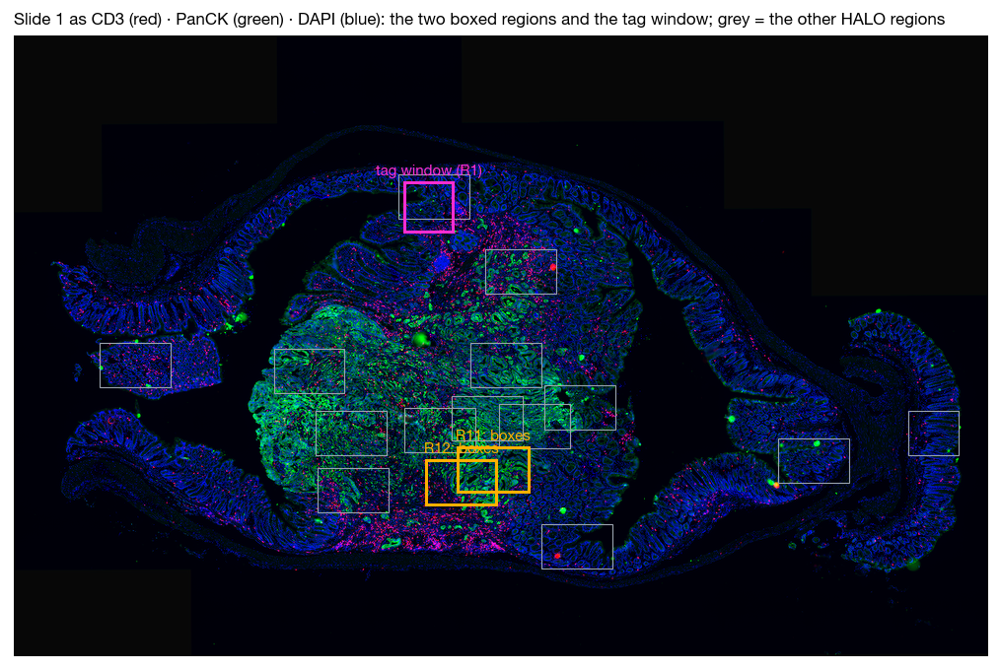

In [3]:
thumb, ds = mx.thumbnail(max_dim=1800, markers=["CD3", "PanCK", "DAPI"])
img = np.zeros((thumb.shape[1], thumb.shape[2], 3), np.float32)
for c in range(3):
    v = thumb[c].astype(np.float32); lo, hi = np.percentile(v[v > 0], [1, 99.7]); img[..., c] = np.clip((v - lo) / (hi - lo), 0, 1)
img = img ** 0.8
fig, ax = plt.subplots(figsize=(9.5, 9.5 * img.shape[0] / img.shape[1]))
ax.imshow(img, interpolation="lanczos"); ax.set_axis_off()
for rid, r in allregions.items():
    b = r.box; hot = rid in REGIONS
    ax.add_patch(Rectangle((b.x0 / ds, b.y0 / ds), b.width / ds, b.height / ds, fill=False, ec="#FFB000" if hot else "#9AA3AD", lw=1.6 if hot else 0.6))
    if hot:
        ax.text(b.x0 / ds + b.width / ds / 2, b.y0 / ds - 6, f"R{rid}: boxes", color="#FFB000", fontsize=8, ha="center", va="bottom", fontweight="bold")
ax.add_patch(Rectangle((wx / ds, wy / ds), wsize / ds, wsize / ds, fill=False, ec=WIN_C, lw=1.6))
ax.text(wx / ds + wsize / ds / 2, wy / ds - 6, "tag window (R1)", color=WIN_C, fontsize=8, ha="center", va="bottom", fontweight="bold")
ax.set_title("Slide 1 as CD3 (red) · PanCK (green) · DAPI (blue): the two boxed regions and the tag window; grey = the other HALO regions")
plt.show()

**Figure 1 — where the labels are.** Regions 11 and 12 (amber) are two of the six reviewed regions of Slide 1 and overlap each other;
the tag window (magenta) lies inside training region 1. Everything here is development-slide data under the protocol.

## 3. Regions 11 and 12 — the boxes over the tissue and over the HALO nuclei

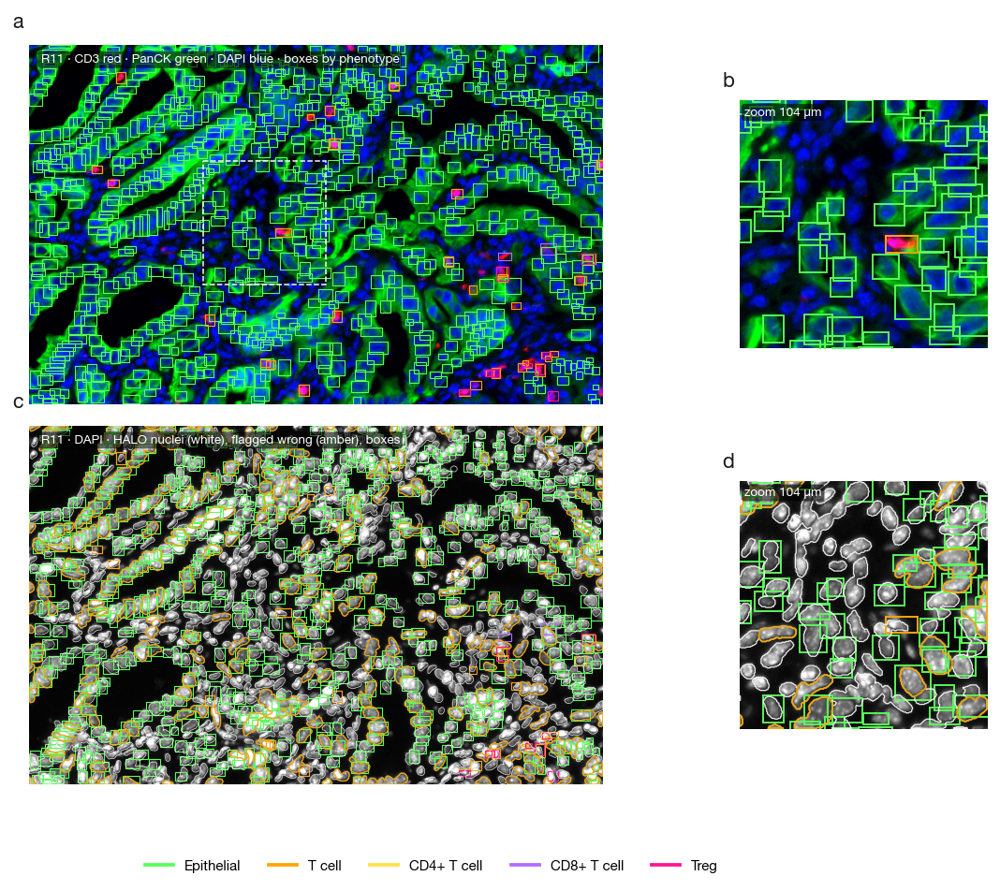

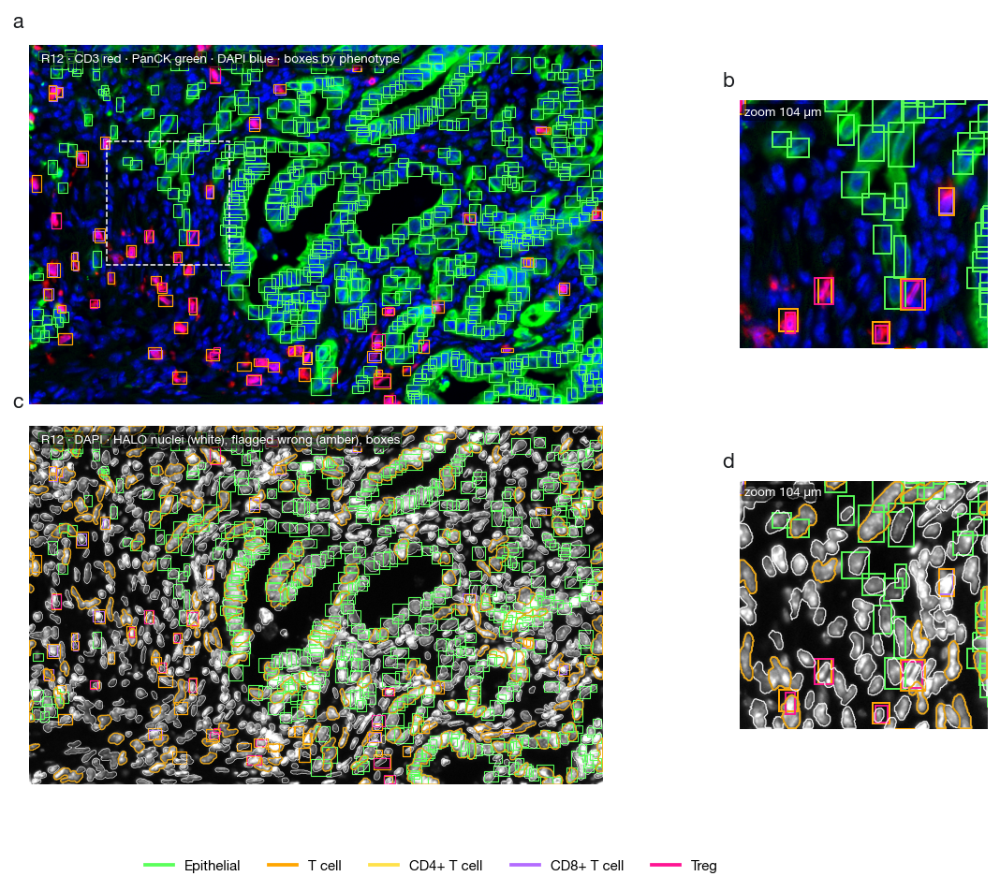

In [4]:
ZS = 320
for rid in REGIONS:
    R = REG[rid]; b = R["box"]; bx = BOX[BOX.region == rid]
    comp = display(render_channels(R["image"], MARKERS, NORMS, ("CD3", "PanCK", "DAPI")).transpose(1, 2, 0), gain=1.5)
    dapi = display(scaled(R["image"][MARKERS.index("DAPI")], *NORMS["DAPI"]), gain=1.6)
    zy, zx = ZOOM[rid]
    fig = plt.figure(figsize=(11, 7.6))
    gs = fig.add_gridspec(2, 3, width_ratios=[1.6, 1.6, 1], hspace=0.06, wspace=0.05)
    a = fig.add_subplot(gs[0, :2]); a.imshow(comp); boxes_on(a, bx, b.x0, b.y0, lw=0.6); a.set_axis_off(); chip(a, f"R{rid} · CD3 red · PanCK green · DAPI blue · boxes by phenotype"); panel(a, "a", dx=-0.01)
    a.add_patch(Rectangle((zx, zy), ZS, ZS, fill=False, ec="white", lw=0.8, ls="--"))
    c = fig.add_subplot(gs[1, :2]); c.imshow(dapi, cmap="gray", vmin=0, vmax=1)
    outlines(c, label_rings(R["labels"]), HALO_C, lw=0.4, alpha=0.8); outlines(c, label_rings(np.where(R["ignore"], R["labels"], 0)), WRONG_C, lw=0.7)
    boxes_on(c, bx, b.x0, b.y0, lw=0.6); c.set_axis_off(); chip(c, f"R{rid} · DAPI · HALO nuclei (white), flagged wrong (amber), boxes"); panel(c, "c", dx=-0.01)
    for k, (src_img, letter) in enumerate(((comp, "b"), (np.repeat(dapi[..., None], 3, 2), "d"))):
        z = fig.add_subplot(gs[k, 2]); z.imshow(src_img[zy:zy + ZS, zx:zx + ZS]); z.set_axis_off(); panel(z, letter, dx=-0.02)
        if k == 1:
            sub = R["labels"][zy:zy + ZS, zx:zx + ZS]; outlines(z, label_rings(sub), HALO_C, lw=0.7); outlines(z, label_rings(np.where(R["ignore"][zy:zy + ZS, zx:zx + ZS], sub, 0)), WRONG_C, lw=1.0)
        boxes_on(z, bx, b.x0 + zx, b.y0 + zy, lw=1.0); z.set_xlim(0, ZS); z.set_ylim(ZS, 0)
        chip(z, f"zoom {ZS * PX_UM:.0f} µm")
    fig.legend(handles=[plt.Line2D([], [], color=PCOLOR[p], lw=2, label=p) for p in ORDER], loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.005))
    plt.show()

**Figure 2 — the boxes on the tissue.** Each row is one region: (a) the gate markers with every box colored by its phenotype, (c) the
same boxes over DAPI with HALO's nuclei (white) and the reviewer's flagged nuclei (amber); (b, d) a zoom. The boxes were drawn in
HALO on this slide: the T-cell boxes sit on CD3-bright cells and the epithelial boxes on the PanCK crypts. A box locates a cell; where it
straddles two nuclei or a flagged merge, the attachment table (section 4) records the ambiguity.

## 4. Box statistics

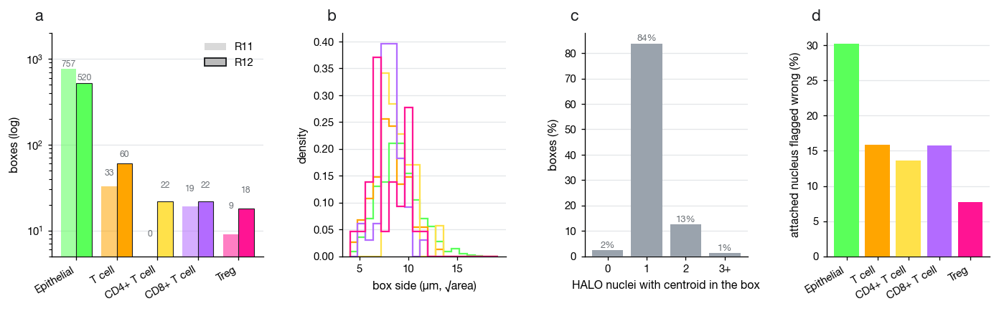

tagged nuclei: 1156 (R11 684, R12 472); 6% carry more than one tag
tags per nucleus (top combinations):
tags
Epithelial                       1071
CD8+ T cell;T cell                 27
T cell                             12
CD4+ T cell;T cell;Treg            11
CD4+ T cell;T cell                 11
T cell;Treg                        10
CD8+ T cell;Epithelial;T cell       7
Treg                                3


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.0), gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1], wspace=0.45))
# (a) counts per phenotype and region
cnt = BOX.groupby(["region", "phenotype"]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
x = np.arange(len(ORDER)); w = 0.38
for i, rid in enumerate(REGIONS):
    ax[0].bar(x + (i - 0.5) * w, cnt.loc[rid].values, w, color=[PCOLOR[p] for p in ORDER], edgecolor=INK if i else "none", lw=0.6, alpha=1 if i else 0.55, label=f"R{rid}", zorder=3)
    for xi, v in zip(x + (i - 0.5) * w, cnt.loc[rid].values):
        ax[0].text(xi, v + 8, str(v), ha="center", va="bottom", fontsize=6.5, color=MUTED)
ax[0].set_xticks(x, ORDER, rotation=30, ha="right"); ax[0].set_yscale("log"); ax[0].set_ylim(5, 2000); ax[0].set_ylabel("boxes (log)"); ygrid(ax[0]); ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="#BBBBBB", alpha=0.55, label="R11"), plt.Rectangle((0, 0), 1, 1, fc="#BBBBBB", ec=INK, label="R12")], loc="upper right"); panel(ax[0], "a")
# (b) box size
sz = np.sqrt((BOX.x1 - BOX.x0) * (BOX.y1 - BOX.y0)) * PX_UM
for ph in ORDER:
    v = sz[BOX.phenotype == ph]
    if len(v): ax[1].hist(v, bins=np.arange(4, 20, 0.8), histtype="step", color=PCOLOR[ph], lw=1.2, label=ph, density=True)
ax[1].set_xlabel("box side (µm, √area)"); ax[1].set_ylabel("density"); ygrid(ax[1]); panel(ax[1], "b")
# (c) nuclei inside a box
nin = ATT.n_nuclei_inside.clip(upper=3).value_counts().sort_index()
ax[2].bar(nin.index, 100 * nin.values / len(ATT), color="#9AA3AD", zorder=3); ax[2].set_xticks([0, 1, 2, 3], ["0", "1", "2", "3+"]); ax[2].set_xlabel("HALO nuclei with centroid in the box"); ax[2].set_ylabel("boxes (%)"); ygrid(ax[2]); panel(ax[2], "c")
for xi, v in zip(nin.index, nin.values): ax[2].text(xi, 100 * v / len(ATT) + 1, f"{100 * v / len(ATT):.0f}%", ha="center", fontsize=7, color=MUTED)
# (d) flagged nuclei among the attached ones, per phenotype
fl = ATT[ATT.nucleus_id > 0].assign(f=lambda d: d.nucleus_flagged.astype(float)).groupby("phenotype").f.mean().reindex(ORDER).fillna(0)
ax[3].bar(np.arange(len(ORDER)), 100 * fl.values, color=[PCOLOR[p] for p in ORDER], zorder=3); ax[3].set_xticks(np.arange(len(ORDER)), ORDER, rotation=30, ha="right"); ax[3].set_ylabel("attached nucleus flagged wrong (%)"); ygrid(ax[3]); panel(ax[3], "d")
plt.show()
co = TAG.assign(t=TAG.tags.str.split(";")).explode("t").groupby("t").size().reindex(ORDER).fillna(0).astype(int)
multi = TAG.tags.str.contains(";").mean()
pairs = TAG.tags.value_counts().head(8)
print(f"tagged nuclei: {len(TAG)} (R11 {int((TAG.region == 11).sum())}, R12 {int((TAG.region == 12).sum())}); {100 * multi:.0f}% carry more than one tag")
print("tags per nucleus (top combinations):"); print(pairs.to_string())

**Figure 3 — what the boxes are like.** (a) Boxes per phenotype and region (log scale): epithelium dominates, the T-cell subsets are
tens of boxes each. (b) Boxes are 8–10 µm across, one cell. (c) Most boxes hold exactly one HALO nucleus centroid; the rest hold
none (a cell HALO missed or merged) or two (packed cells). (d) A quarter of the epithelial boxes sit on nuclei the reviewer flagged
as wrong, the same rate as the region overall, so the tags are not biased toward clean nuclei. Tag combinations follow the
hierarchy: CD4⁺/CD8⁺/Treg boxes usually also carry a T-cell box; a few epithelial boxes coincide with T-cell boxes where an
intraepithelial lymphocyte sits on a crypt nucleus.

## 5. Do the gate markers agree with the tags? (calibration preview)

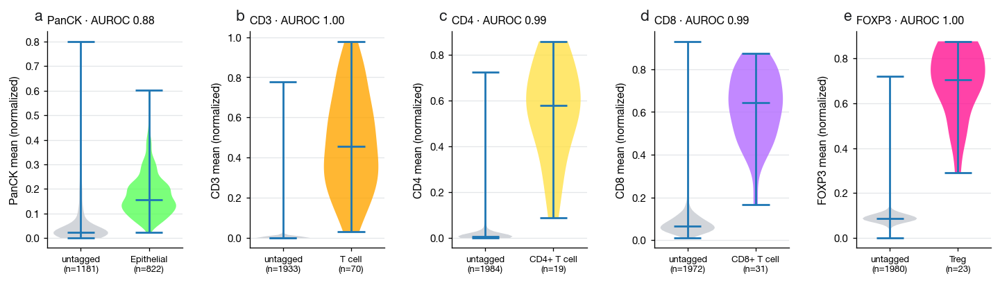

In [6]:
# per-nucleus mean of every panel marker, in the dataset's normalized units, for both regions
recs = []
for rid in REGIONS:
    R = REG[rid]; ids = R["ids"]
    means = {m: ndi.mean(scaled(R["image"][MARKERS.index(m)], *NORMS[m]), R["labels"], ids) for m in MARKERS if m in GATE.values()}
    tg = TAG[TAG.region == rid].set_index("nucleus_id").tags
    for j, i in enumerate(ids):
        recs.append({"region": rid, "nucleus_id": int(i), "flagged": bool(R["flagged"][j]), "tags": tg.get(int(i), ""), **{m: float(means[m][j]) for m in means}})
CELLS = pd.DataFrame(recs); CELLS = CELLS[~CELLS.flagged]                       # confirmed nuclei only
def auroc(pos, neg):
    if len(pos) < 3 or len(neg) < 3: return np.nan
    return mannwhitneyu(pos, neg, alternative="greater").statistic / (len(pos) * len(neg))
fig, ax = plt.subplots(1, len(ORDER), figsize=(13, 3.0), gridspec_kw=dict(wspace=0.5))
for k, ph in enumerate(ORDER):
    m = GATE[ph]; has = CELLS.tags.str.contains(ph, regex=False)
    pos, neg = CELLS.loc[has, m], CELLS.loc[~has, m]
    parts = ax[k].violinplot([neg.values, pos.values] if len(pos) else [neg.values], positions=[0, 1] if len(pos) else [0], showmedians=True, widths=0.8)
    for pc, col in zip(parts["bodies"], ["#C7CBD1", PCOLOR[ph]]): pc.set_facecolor(col); pc.set_alpha(0.8)
    ax[k].set_xticks([0, 1], [f"untagged\n(n={len(neg)})", f"{ph}\n(n={len(pos)})"], fontsize=7); ax[k].set_ylabel(f"{m} mean (normalized)"); ygrid(ax[k])
    ax[k].set_title(f"{m} · AUROC {auroc(pos.values, neg.values):.2f}" if len(pos) else f"{m} · no tags", fontsize=8.5); panel(ax[k], "abcde"[k])
plt.show()

**Figure 4 — the gate marker of each phenotype, tagged against untagged confirmed nuclei of regions 11 and 12.** The AUROC says how
well the single marker separates the tagged cells: CD3 and FOXP3 separate their tags perfectly (AUROC 1.00), CD4 and CD8 nearly so
(0.99), and PanCK separates the epithelium well (0.88) but not cleanly, because crypt epithelium stains unevenly and the tagged cells
include intraepithelial lymphocytes. This is a far better calibration set than the window of set A, where CD8 reached 0.42 and PanCK
0.74: two whole reviewed regions with HALO nuclei underneath. The untagged cells are *not* guaranteed negatives for the rarer
phenotypes (a session need not have boxed every T cell), so precision is the more trustworthy readout for them.

## 6. The window of set A

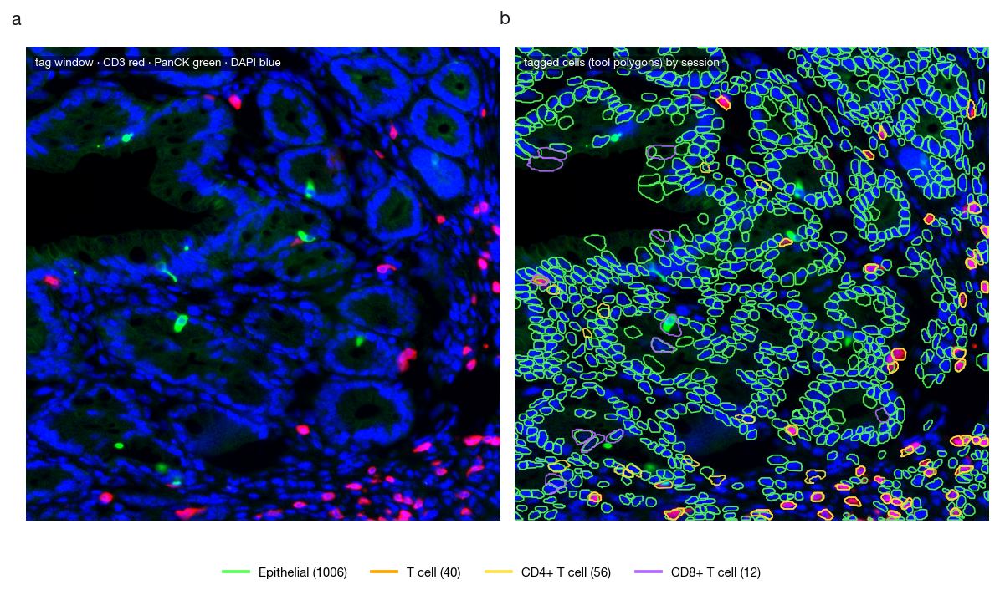

In [7]:
Wb = mx.read_region(__import__("mxdata.io", fromlist=["Box"]).Box(wx, wy, wx + wsize, wy + wsize), MARKERS, 0)
comp = display(render_channels(Wb, MARKERS, NORMS, ("CD3", "PanCK", "DAPI")).transpose(1, 2, 0), gain=1.5)
fig, ax = plt.subplots(1, 2, figsize=(11, 5.6), gridspec_kw=dict(wspace=0.03))
ax[0].imshow(comp); ax[0].set_axis_off(); chip(ax[0], "tag window · CD3 red · PanCK green · DAPI blue"); panel(ax[0], "a", dx=-0.01)
ax[1].imshow(comp); ax[1].set_axis_off(); chip(ax[1], "tagged cells (tool polygons) by session"); panel(ax[1], "b", dx=-0.01)
WIN = {ph: load_geojson(SLIDE, "W1", ph) for ph in ORDER if ph in set(L35[L35.area == "W1"].phenotype)}
for ph, fc in WIN.items():
    rings = [np.asarray(shape(f["geometry"]).exterior.coords, float)[:, :2] - [wx, wy] for f in fc["features"]]
    outlines(ax[1], rings, PCOLOR[ph], lw=0.9)
ax[1].set_xlim(0, wsize); ax[1].set_ylim(wsize, 0)
fig.legend(handles=[plt.Line2D([], [], color=PCOLOR[p], lw=2, label=f"{p} ({len(WIN[p]['features'])})") for p in WIN], loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.01))
plt.show()

**Figure 5 — the earlier window (area W1).** One 333 µm window in region 1, tagged in the annotation tool (its own segmentation, not
HALO's): PanCK⁺ cells cover the crypts, the T-cell sessions tag a few dozen cells. In the store its polygons are attached to the HALO
nuclei of region 1 where the window overlaps it (nucleus_id 0 in the strip below). It stays useful as a second, independent check of the gates,
but the boxes of regions 11 and 12 supersede it as calibration data: they cover whole reviewed regions with HALO nuclei underneath.

## 7. Slide 2 — the four tool windows of the test slide

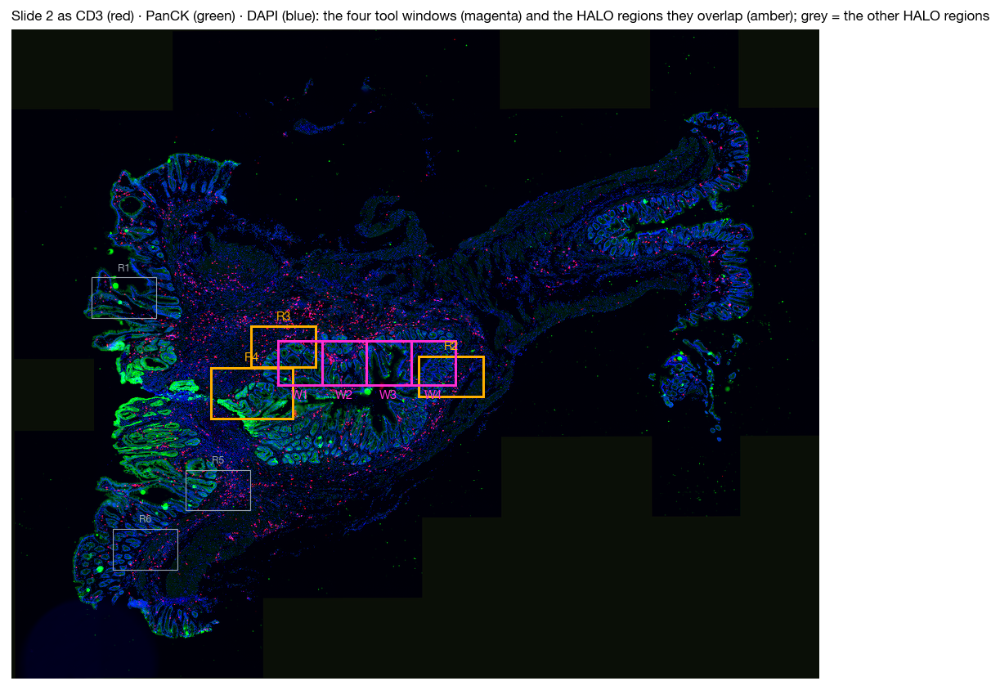

SLIDE-0236: 6 HALO regions (6 reviewed), all in the test split | windows: W1 at (6144, 7168) over R[3, 4], W2 at (7168, 7168) over no region, W3 at (8192, 7168) over no region, W4 at (9216, 7168) over R[2]


In [8]:
from mxdata.io import Box

SLIDE2 = "SLIDE-0236"
paths36, mx36, _ = ingest(SLIDE2, None); PX_UM36 = float(mx36.pixel_size_um or 0.325)
stats36 = NormStats.load(DATASET / SLIDE2 / "stats.json"); NORMS36 = {m: (stats36.lo[m], stats36.hi[m]) for m in MARKERS}
regions36 = {r.region_id: r for r in load_regions(paths36, None, cfg.min_area_px)}
WIN36 = {a: (int(r.x0), int(r.y0), int(r.x1 - r.x0)) for a, r in A36.iterrows()}          # area -> (x0, y0, size)
hot36 = sorted(set(L36.region_id[L36.region_id > 0]))                                  # the HALO regions the windows overlap
thumb, ds = mx36.thumbnail(max_dim=1800, markers=["CD3", "PanCK", "DAPI"])
img = np.zeros((thumb.shape[1], thumb.shape[2], 3), np.float32)
for c in range(3):
    v = thumb[c].astype(np.float32); lo, hi = np.percentile(v[v > 0], [1, 99.7]); img[..., c] = np.clip((v - lo) / (hi - lo), 0, 1)
img = img ** 0.8
fig, ax = plt.subplots(figsize=(9.5, 9.5 * img.shape[0] / img.shape[1]))
ax.imshow(img, interpolation="lanczos"); ax.set_axis_off()
for rid, r in regions36.items():
    b = r.box; hot = rid in hot36
    ax.add_patch(Rectangle((b.x0 / ds, b.y0 / ds), b.width / ds, b.height / ds, fill=False, ec="#FFB000" if hot else "#9AA3AD", lw=1.6 if hot else 0.6))
    ax.text(b.x0 / ds + b.width / ds / 2, b.y0 / ds - 6, f"R{rid}", color="#FFB000" if hot else "#9AA3AD", fontsize=8 if hot else 6.5, ha="center", va="bottom", fontweight="bold")
for a, (wx, wy, ws) in WIN36.items():
    ax.add_patch(Rectangle((wx / ds, wy / ds), ws / ds, ws / ds, fill=False, ec=WIN_C, lw=1.6))
    ax.text(wx / ds + ws / ds / 2, (wy + ws) / ds + 6, a, color=WIN_C, fontsize=8, ha="center", va="top", fontweight="bold")
ax.set_title("Slide 2 as CD3 (red) · PanCK (green) · DAPI (blue): the four tool windows (magenta) and the HALO regions they overlap (amber); grey = the other HALO regions")
plt.show()
print(f"{SLIDE2}: {len(regions36)} HALO regions ({sum(r.has_qc for r in regions36.values())} reviewed), all in the test split | windows: "
      + ", ".join(f"{a} at ({wx}, {wy}) over " + (f"R{sorted(set(L36.region_id[(L36.area == a) & (L36.region_id > 0)]))}" if (L36.region_id[L36.area == a] > 0).any() else "no region") for a, (wx, wy, ws) in WIN36.items()))

**Figure 6 — where the Slide 2 labels are.** The four tool windows (magenta, 1024² = 333 µm each) sit side by side on one row across the
crypt–stroma band in the middle of the test slide. Only two of them touch a HALO region: W1 straddles regions 3 and 4, W4 lies inside region
2 (amber); W2 and W3 fall in the gap between the regions, so their polygons have no HALO nucleus to attach to (`nucleus_id` 0, `region_id` 0).
All six regions of this slide are reviewed and all are test split under the protocol, so nothing here is ever used for calibration.

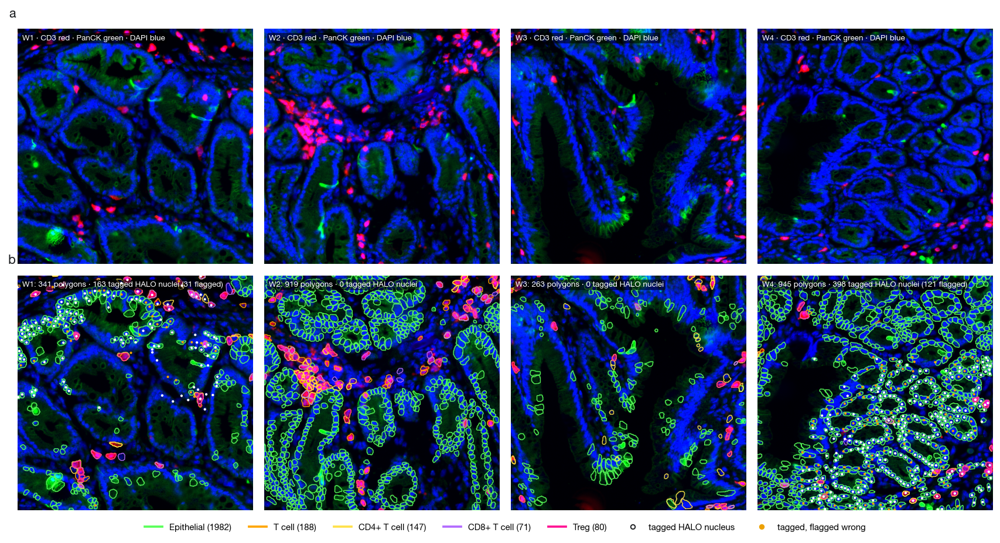

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.7), gridspec_kw=dict(wspace=0.03, hspace=0.05))
fig.subplots_adjust(left=0.005, right=0.995, top=0.97, bottom=0.06)
for j, (a, (wx, wy, ws)) in enumerate(WIN36.items()):
    Wb = mx36.read_region(Box(wx, wy, wx + ws, wy + ws), MARKERS, 0)
    comp = display(render_channels(Wb, MARKERS, NORMS36, ("CD3", "PanCK", "DAPI")).transpose(1, 2, 0), gain=1.5)
    axes[0, j].imshow(comp); chip(axes[0, j], f"{a} · CD3 red · PanCK green · DAPI blue")
    axes[1, j].imshow(comp)
    for ph in ORDER:
        fc = load_geojson(SLIDE2, a, ph)
        rings = [np.asarray(shape(f["geometry"]).exterior.coords, float)[:, :2] - [wx, wy] for f in fc["features"]]
        outlines(axes[1, j], rings, PCOLOR[ph], lw=0.8)
    t = N36[N36.area == a]
    if len(t):
        axes[1, j].scatter(t.cx - wx, t.cy - wy, s=5, c=[WRONG_C if f else HALO_C for f in t.flagged], lw=0, zorder=4)
    axes[1, j].set_xlim(0, ws); axes[1, j].set_ylim(ws, 0)
    chip(axes[1, j], f"{a}: {int((L36.area == a).sum())} polygons · {len(t)} tagged HALO nuclei" + (f" ({int(t.flagged.sum())} flagged)" if len(t) else ""))
    for ax_ in axes[:, j]:
        ax_.set_axis_off()
panel(axes[0, 0], "a", dx=-0.01); panel(axes[1, 0], "b", dx=-0.01)
fig.legend(handles=[plt.Line2D([], [], color=PCOLOR[p], lw=2, label=f"{p} ({int((L36.phenotype == p).sum())})") for p in ORDER]
                   + [plt.Line2D([], [], marker="o", ls="", ms=4, color=HALO_C, markeredgecolor=INK, label="tagged HALO nucleus"),
                      plt.Line2D([], [], marker="o", ls="", ms=4, color=WRONG_C, label="tagged, flagged wrong")],
           loc="lower center", ncol=7, bbox_to_anchor=(0.5, 0.005))
plt.show()

**Figure 7 — the four windows, as stored.** (a) Each window as CD3 (red) · PanCK (green) · DAPI (blue) with the test slide's normalization.
(b) The same with every polygon of the store outlined in its phenotype color (the tool's own `instanseg` segmentation, one exhaustive session per
phenotype, only the tagged cells exported) and, where a HALO region lies underneath, the tagged HALO nuclei as dots (white = confirmed, amber =
flagged wrong by the reviewer). Epithelial polygons trace the crypts, the T-cell family sits in the CD3-bright stroma — W2 is the immune-rich
window with 100 T cells, W4 the crypt-packed one with 873 epithelial cells. In W1 the dots stop where regions 3 and 4 end: the lower-right part
of the window has polygons but no HALO reference, which is why under half of W1's polygons resolve to a nucleus.

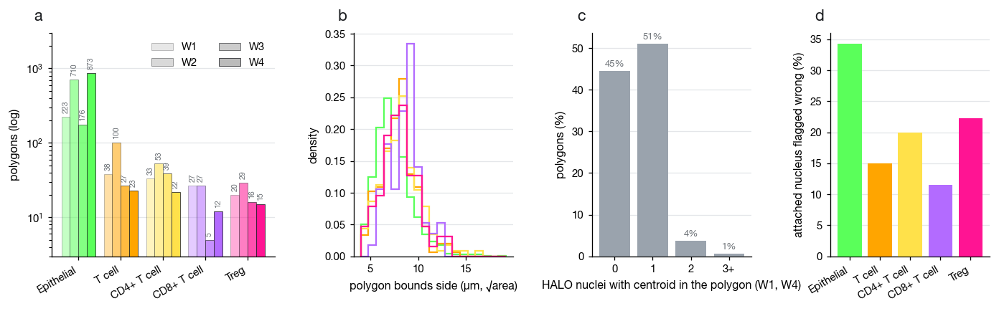

Slide 2: 2468 polygons; 713 land on a HALO nucleus (W1 67 %, W4 51 %; W2, W3 none) -> 561 tagged HALO nuclei (W1 163, W4 398), 27 % of them flagged wrong; 7 % carry more than one tag
tags per nucleus (top combinations):
tags
Epithelial                             514
CD4+ T cell;CD8+ T cell;T cell;Treg     14
CD4+ T cell;T cell;Treg                  6
CD4+ T cell;CD8+ T cell;T cell           4
CD4+ T cell                              4
T cell                                   4
CD4+ T cell;T cell                       3
CD8+ T cell;T cell                       2
tagged nuclei per phenotype: Epithelial 520, T cell 39, CD4+ T cell 38, CD8+ T cell 26, Treg 26


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.0), gridspec_kw=dict(width_ratios=[1.4, 1, 1, 1], wspace=0.45))
# (a) labels per window and phenotype
cnt36 = L36.groupby(["area", "phenotype"]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
x = np.arange(len(ORDER)); w = 0.2; alphas = [0.35, 0.55, 0.75, 1.0]
for i, a in enumerate(cnt36.index):
    ax[0].bar(x + (i - 1.5) * w, cnt36.loc[a].values, w, color=[PCOLOR[p] for p in ORDER], alpha=alphas[i], edgecolor=INK, lw=0.4, zorder=3)
    for xi, v in zip(x + (i - 1.5) * w, cnt36.loc[a].values):
        if v: ax[0].text(xi, v * 1.12, str(v), ha="center", va="bottom", fontsize=5.6, color=MUTED, rotation=90)
ax[0].set_xticks(x, ORDER, rotation=30, ha="right"); ax[0].set_yscale("log"); ax[0].set_ylim(3, 3000); ax[0].set_ylabel("polygons (log)"); ygrid(ax[0])
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="#BBBBBB", alpha=al, ec=INK, lw=0.4, label=a) for a, al in zip(cnt36.index, alphas)], loc="upper right", ncol=2); panel(ax[0], "a")
# (b) polygon size (side of the bounding box, as for the boxes of Slide 1)
sz36 = np.sqrt((L36.x1 - L36.x0) * (L36.y1 - L36.y0)) * PX_UM36
for ph in ORDER:
    v = sz36[L36.phenotype == ph]
    if len(v): ax[1].hist(v, bins=np.arange(4, 20, 0.8), histtype="step", color=PCOLOR[ph], lw=1.2, label=ph, density=True)
ax[1].set_xlabel("polygon bounds side (µm, √area)"); ax[1].set_ylabel("density"); ygrid(ax[1]); panel(ax[1], "b")
# (c) HALO nuclei with centroid inside a polygon, where HALO nuclei exist (W1, W4)
ATT36 = L36[L36.area.isin(A36.index[A36.n_nuclei > 0])]
nin = ATT36.n_nuclei_inside.clip(upper=3).value_counts().sort_index().reindex([0, 1, 2, 3], fill_value=0)
ax[2].bar(nin.index, 100 * nin.values / len(ATT36), color="#9AA3AD", zorder=3); ax[2].set_xticks([0, 1, 2, 3], ["0", "1", "2", "3+"])
ax[2].set_xlabel("HALO nuclei with centroid in the polygon (W1, W4)"); ax[2].set_ylabel("polygons (%)"); ygrid(ax[2]); panel(ax[2], "c")
for xi, v in zip(nin.index, nin.values): ax[2].text(xi, 100 * v / len(ATT36) + 1, f"{100 * v / len(ATT36):.0f}%", ha="center", fontsize=7, color=MUTED)
# (d) flagged nuclei among the attached ones, per phenotype
fl36 = ATT36[ATT36.nucleus_id > 0].assign(f=lambda d: d.nucleus_flagged.astype(float)).groupby("phenotype").f.mean().reindex(ORDER).fillna(0)
ax[3].bar(np.arange(len(ORDER)), 100 * fl36.values, color=[PCOLOR[p] for p in ORDER], zorder=3); ax[3].set_xticks(np.arange(len(ORDER)), ORDER, rotation=30, ha="right")
ax[3].set_ylabel("attached nucleus flagged wrong (%)"); ygrid(ax[3]); panel(ax[3], "d")
plt.show()
co36 = N36.assign(t=N36.tags.str.split(";")).explode("t").groupby("t").size().reindex(ORDER).fillna(0).astype(int)
print(f"Slide 2: {len(L36)} polygons; {int((L36.nucleus_id > 0).sum())} land on a HALO nucleus (W1 {100 * (L36[L36.area == 'W1'].nucleus_id > 0).mean():.0f} %, "
      f"W4 {100 * (L36[L36.area == 'W4'].nucleus_id > 0).mean():.0f} %; W2, W3 none) -> {len(N36)} tagged HALO nuclei "
      f"(W1 {int((N36.area == 'W1').sum())}, W4 {int((N36.area == 'W4').sum())}), {100 * N36.flagged.astype(bool).mean():.0f} % of them flagged wrong; "
      f"{100 * N36.tags.str.contains(';').mean():.0f} % carry more than one tag")
print("tags per nucleus (top combinations):"); print(N36.tags.value_counts().head(8).to_string())
print("tagged nuclei per phenotype:", ", ".join(f"{p} {n}" for p, n in co36.items()))

**Figure 8 — what the Slide 2 labels are like.** (a) Polygons per phenotype and window (log scale): epithelium dominates everywhere, the T-cell
subsets are tens of cells per window, and the four windows together hold more T-cell-family labels (188 T cell, 147 CD4⁺, 71 CD8⁺, 80 Treg) than
regions 11 and 12 of Slide 1 do. (b) Polygon bounds are 6–10 µm across — one cell, the same scale as the HALO boxes of Slide 1 (Figure 3b).
(c) In the two windows with HALO nuclei underneath (W1, W4), half of the polygons hold exactly one HALO nucleus centroid, 5 % hold two or more
(packed crypt cells), and the rest hold none — mostly the part of W1 outside regions 3 and 4, plus cells HALO missed. (d) Among the attached
nuclei, a third of the epithelial ones and 12–22 % of the T-cell ones are nuclei the reviewer flagged as wrong, so the tags are not biased toward
clean nuclei here either. Tag combinations follow the hierarchy (a CD4⁺/CD8⁺/Treg nucleus usually also carries a T-cell tag; 7 % of the tagged
nuclei carry more than one tag). Because the untagged cells of a session are not exported, there is no per-cell negative set on this slide: the
negatives are implied by the exhaustive-session convention (`negatives_defined = True`), and no gate is ever tuned on them.

## 8. Slide 3, field 4 — in the HALO frame

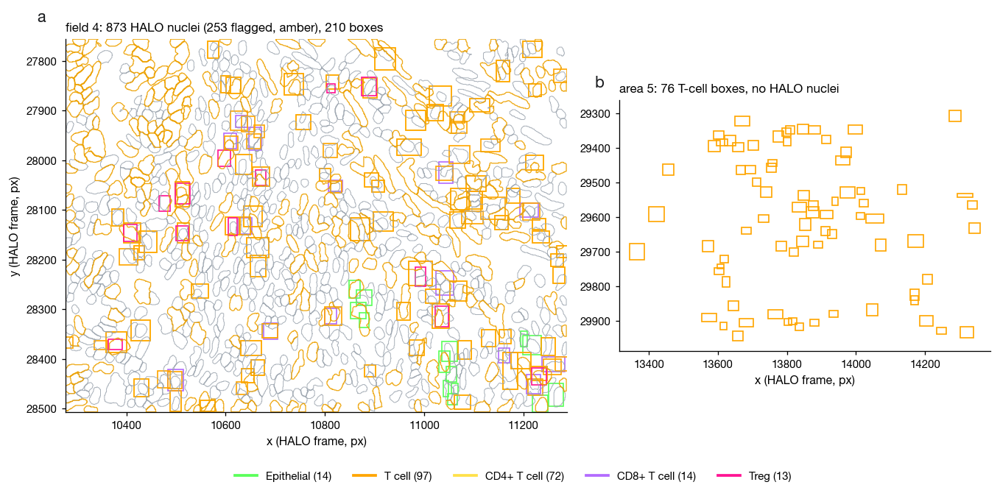

field 4: 109 tagged nuclei (25 flagged); boxes with 2+ nuclei inside: 78 of 210


In [11]:
nuc = json.load(open(phenotyping_dir("SLIDE-0233") / "geojson" / "R4_HALO_nuclei.geojson"))["features"]
def ring_of(geom):
    g = shape(geom)
    if g.geom_type == "MultiPolygon": g = max(g.geoms, key=lambda q: q.area)
    return np.asarray(g.exterior.coords, float)[:, :2]
rings = [ring_of(f["geometry"]) for f in nuc]; flg = np.array([bool(f["properties"].get("flagged")) for f in nuc])
b4 = L33[L33.area == "R4"]; a5 = L33[L33.area == "A5"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw=dict(width_ratios=[1.35, 1], wspace=0.12))
outlines(ax[0], [r for r, f in zip(rings, flg) if not f], "#9AA3AD", lw=0.5); outlines(ax[0], [r for r, f in zip(rings, flg) if f], WRONG_C, lw=0.7)
boxes_on(ax[0], b4, lw=0.9); ax[0].set_xlim(10278, 11287); ax[0].set_ylim(28507, 27756); ax[0].set_aspect("equal"); ax[0].set_xlabel("x (HALO frame, px)"); ax[0].set_ylabel("y (HALO frame, px)")
ax[0].set_title(f"field 4: {len(nuc)} HALO nuclei ({int(flg.sum())} flagged, amber), {len(b4)} boxes"); panel(ax[0], "a")
boxes_on(ax[1], a5, lw=0.9); ax[1].set_xlim(a5.x0.min() - 30, a5.x1.max() + 30); ax[1].set_ylim(a5.y1.max() + 30, a5.y0.min() - 30); ax[1].set_aspect("equal"); ax[1].set_xlabel("x (HALO frame, px)")
ax[1].set_title(f"area 5: {len(a5)} T-cell boxes, no HALO nuclei"); panel(ax[1], "b")
fig.legend(handles=[plt.Line2D([], [], color=PCOLOR[p], lw=2, label=f"{p} ({int((b4.phenotype == p).sum())})") for p in ORDER], loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
plt.show()
print(f"field 4: {len(TAG33)} tagged nuclei ({int(TAG33.flagged.eq(True).sum())} flagged); boxes with 2+ nuclei inside: {int((ATT33.n_nuclei_inside >= 2).sum())} of {len(ATT33)}")

**Figure 9 — Slide 3, field 4 in the HALO frame.** The field-4 boxes and HALO nuclei are drawn in the coordinate frame HALO used (scan
region 1 of the slide, `frame = HALO-R1` in `areas.csv`), with no image underneath: the attachment of boxes to nuclei is purely geometric and
does not need one. Field 2 (R2) is in the store in the same frame with the same schema; `areas.csv` records whether the images of that
scan region are available, which is what decides when the fields can be scored on pixels.

## Summary

* **Usable now (development slide):** regions 11 and 12 with 1,460 boxes on 1,156 tagged HALO nuclei (Epithelial 1,277, T cell 93,
  CD4⁺ 22, CD8⁺ 41, Treg 27) plus the region-1 window (1,114 tagged polygons). These calibrate the panel gates; PanCK, CD8 and FOXP3 were provisional.
* **Test slide (Slide 2):** four tool windows with 2,468 polygons (Epithelial 1,982, T cell 188, CD4⁺ 147, CD8⁺ 71, Treg 80), 561 of
  them resolved to tagged HALO nuclei where a window overlaps a HALO region (W1 over R3 + R4, W4 over R2); W2 and W3 have polygons only.
  Scoring data under the protocol — never used to set a gate.
* **One store, one schema:** `load_labels(slide)` / `load_tagged_nuclei(slide)` give everything above for any slide; `scripts/build_phenotyping.py`
  rebuilds the store from `original_delivery/` when a new session or field arrives.
* **Missing:** CD4 boxes for region 11 (empty export); on Slide 2 the untagged cells of each session are not exported, so negatives
  there are implied by the exhaustive-session convention, not listed.
* Boxes locate cells and never define boundaries: a box with two nuclei or a flagged nucleus is kept and marked in `*_boxes_to_halo_nuclei.csv`.